# 47 — The thesis analysis document (LaTeX → PDF)

Writes `<output>/thesis_document/main.tex` from the text modules (`viz/thesis_text_common.py`, `viz/thesis_text_qN.py`),
the item registers (`viz/thesis_qN.py`) and what notebook 46 saved (graphs, tables, numbers), then compiles it with
tectonic (path in `labelling_analysis.yaml: tools.tectonic`).

Structure: Methodology → Results and discussion (three parts, seven questions, Answer box each) → Limitations →
Appendix by question. Yellow = the author's open decisions (decide / verify / drop). It computes nothing: run notebook 46 first.

In [1]:
import sys, pathlib
PILLAR = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(PILLAR))
import pandas as pd
from IPython.display import display, Image
from viz import config, thesis_doc
cfg = config.load()

## Build and compile

In [2]:
pdf, report = thesis_doc.build(cfg)
print(report['pages'], 'pages ->', pdf)
print(report['items'], 'items placed;', len(report['missing']), 'missing')
for m in report['missing']: print('  missing:', m)

51 pages -> /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_document/main.pdf
68 items placed; 0 missing


## The author's open decisions (yellow in the PDF)

In [3]:
pd.DataFrame(report['flags'], columns=['question', 'item', 'flag', 'note'])

,question,item,flag,note
0,Q2,q2_largest_filer_per_class,decide,Author decides: the table may be redundant wit...
1,Q3,q3_region_entry_lag,verify,verify: an interval touching 0 is read here as...
2,Q4,q4_patent_vs_market_clock,decide,main text or appendix
3,Q4,q4_trl_representativeness,verify,author re-verifies these values and the evtol....
4,Q4,q4_index_firm_representativeness,verify,author re-verifies these values and the evtol....
5,Q6,q6_selected_fields,decide,Table 6 and Figure 6 (i) say the same thing fr...
6,Q7,q7_cannot_answer,drop,limitations table
7,Q3,q3_region_mix_by_window_class,decide,the index wrote 'Figure 21' here; the per-wind...
8,Q3,q3_region_mix_by_window_units,decide,the index wrote 'Figure 21' here; the per-wind...
9,Q3,q3_region_mix_by_window_tilting,decide,the index wrote 'Figure 21' here; the per-wind...


## A look at the pages

51 pages rendered to /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_document/preview


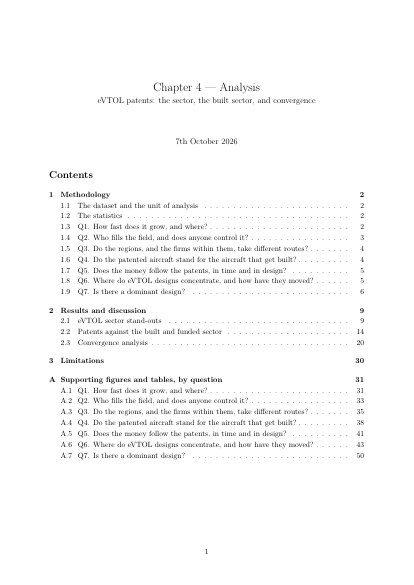

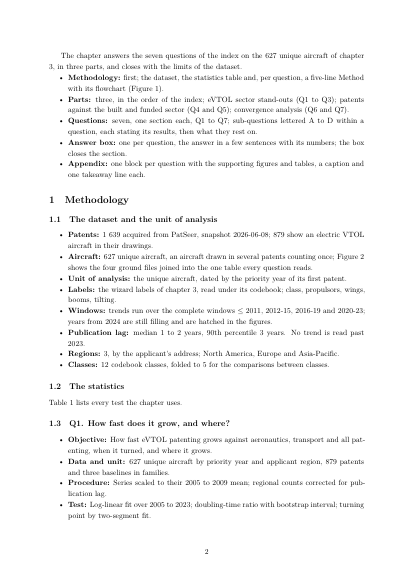

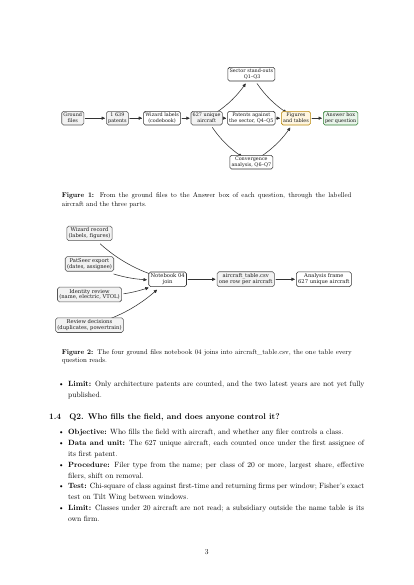

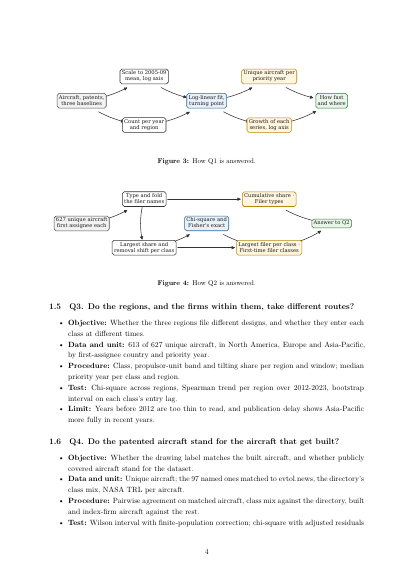

In [4]:
pages = thesis_doc.pages_png(pdf, pdf.parent / 'preview', dpi=50)
print(len(pages), 'pages rendered to', pages[0].parent)
for p in pages[:4]:
    display(Image(filename=str(p), width=380))